#### Data Collection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("student_lifestyle_dataset.csv")

features = [
    "Study_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
    "Social_Hours_Per_Day"
]

print(df.head())
print("Dataset shape:", df.shape)

X = df[features]
y = df["GPA"]

   Student_ID  Study_Hours_Per_Day  Extracurricular_Hours_Per_Day  \
0           1                  6.9                            3.8   
1           2                  5.3                            3.5   
2           3                  5.1                            3.9   
3           4                  6.5                            2.1   
4           5                  8.1                            0.6   

   Sleep_Hours_Per_Day  Social_Hours_Per_Day  Physical_Activity_Hours_Per_Day  \
0                  8.7                   2.8                              1.8   
1                  8.0                   4.2                              3.0   
2                  9.2                   1.2                              4.6   
3                  7.2                   1.7                              6.5   
4                  6.5                   2.2                              6.6   

    GPA Stress_Level  
0  2.99     Moderate  
1  2.75          Low  
2  2.67          Low  
3  2.8

#### Data Cleaning

In [2]:
print("Missing values:")
print(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

X = df[features]
y = df["GPA"]

Missing values:
Student_ID                         0
Study_Hours_Per_Day                0
Extracurricular_Hours_Per_Day      0
Sleep_Hours_Per_Day                0
Social_Hours_Per_Day               0
Physical_Activity_Hours_Per_Day    0
GPA                                0
Stress_Level                       0
dtype: int64
Duplicate rows: 0


#### Treating the Categorical Variables

In [6]:
import pandas as pd

df = pd.read_csv("student_lifestyle_dataset.csv")

df["GPA_Category"] = (df["GPA"] >= 3.00).astype(int)

print(df["GPA_Category"].value_counts().sort_index())

GPA_Category
0     712
1    1288
Name: count, dtype: int64


#### Splitting the Dataset

In [9]:
from sklearn.model_selection import train_test_split

features = [
    "Study_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
    "Social_Hours_Per_Day"
]

X = df[features]
y = df["GPA"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1600
Testing records: 400


#### 5. Featuring the Dataset — Feature Scaling

In [12]:
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (X_train < Q1 - 1.5 * IQR)
    | (X_train > Q3 + 1.5 * IQR)
).any(axis=1)

print("Training outliers:", outliers.sum())

X_train = X_train.loc[~outliers]
y_train = y_train.loc[X_train.index]

yc_train = df.loc[X_train.index, "GPA_Category"]
yc_test = df.loc[X_test.index, "GPA_Category"]

Training outliers: 0


#### Loading and Preprocessing the Data

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.metrics import mean_squared_error, r2_score

# Load the dataset
df = pd.read_csv("student_lifestyle_dataset.csv")

# Select the independent variables
features = [
    "Study_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
    "Social_Hours_Per_Day"
]

# Check missing values and duplicates
print("Missing values:")
print(df[features + ["GPA"]].isna().sum())

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Separate independent and dependent variables
X = df[features]
y = df["GPA"]

print("Number of records:", len(df))

Missing values:
Study_Hours_Per_Day              0
Sleep_Hours_Per_Day              0
Extracurricular_Hours_Per_Day    0
Social_Hours_Per_Day             0
GPA                              0
dtype: int64
Duplicate rows: 0
Number of records: 2000


#### Detecting and Removing Outliers

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = (
    (X_train < lower_limit)
    | (X_train > upper_limit)
).any(axis=1)

print("Training outliers:", outliers.sum())

X_train = X_train.loc[~outliers]
y_train = y_train.loc[X_train.index]

Training outliers: 0


#### Splitting the Data

In [16]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Standardize the independent variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training records: 1600
Testing records: 400


#### Applying Regression Models

In [17]:
reg_models = {
    "Multiple Linear Regression": LinearRegression(),

    "Ridge": Ridge(alpha=1.0),

    "Lasso": Lasso(
        alpha=0.01,
        max_iter=10000
    ),

    "Elastic Net": ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=10000
    )
}

# Train the four models
for name, model in reg_models.items():
    model.fit(X_train_scaled, y_train)

# Create degree-2 polynomial features
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# Train Polynomial Regression
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

reg_models["Polynomial Degree 2"] = poly_model

print("All five regression models have been trained.")

All five regression models have been trained.


#### Evaluating Models


In [18]:
results = []
predictions = {}

for name, model in reg_models.items():

    if name == "Polynomial Degree 2":
        y_pred = model.predict(X_test_poly)
    else:
        y_pred = model.predict(X_test_scaled)

    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append([name, mse, r2])

reg_table = pd.DataFrame(
    results,
    columns=["Model", "MSE", "R2"]
)

print(reg_table.to_string(index=False))

                     Model      MSE       R2
Multiple Linear Regression 0.042058 0.549519
                     Ridge 0.042060 0.549506
                     Lasso 0.042216 0.547833
               Elastic Net 0.042171 0.548307
       Polynomial Degree 2 0.042905 0.540452


#### Selecting the Best Model

In [19]:
reg_table = reg_table.sort_values(
    "R2",
    ascending=False
)

best_reg_name = reg_table.iloc[0]["Model"]
best_reg = reg_models[best_reg_name]
best_pred = predictions[best_reg_name]

print(reg_table.to_string(index=False))

print("\nBest model:", best_reg_name)
print("Best R2:", reg_table.iloc[0]["R2"])
print("Best MSE:", reg_table.iloc[0]["MSE"])

# Compare actual and predicted GPA
comparison = pd.DataFrame({
    "Student_ID": df.loc[X_test.index, "Student_ID"],
    "Actual GPA": y_test,
    "Predicted GPA": best_pred
})

print("\nActual versus predicted values:")
print(comparison.head())

                     Model      MSE       R2
Multiple Linear Regression 0.042058 0.549519
                     Ridge 0.042060 0.549506
               Elastic Net 0.042171 0.548307
                     Lasso 0.042216 0.547833
       Polynomial Degree 2 0.042905 0.540452

Best model: Multiple Linear Regression
Best R2: 0.5495191558155232
Best MSE: 0.042058348637043164

Actual versus predicted values:
      Student_ID  Actual GPA  Predicted GPA
1860        1861        2.88       2.904404
353          354        3.12       2.863963
1333        1334        3.41       3.436231
905          906        3.11       3.087397
1289        1290        3.19       3.323500


#### Printing the Regression Equation



In [20]:
# Convert the coefficients to the original units of hours
coefficients = best_reg.coef_ / scaler.scale_

# Convert the intercept to the original units
intercept = (
    best_reg.intercept_
    - np.dot(coefficients, scaler.mean_)
)

# Display the intercept and coefficients
print(f"Intercept: {intercept:.6f}")

for feature, coefficient in zip(features, coefficients):
    print(f"{feature}: {coefficient:.6f}")

# Print the complete regression equation
print("\nRegression Equation:")

print(
    f"Predicted GPA = {intercept:.6f}"
    f" {coefficients[0]:+.6f} * Study_Hours_Per_Day"
    f" {coefficients[1]:+.6f} * Sleep_Hours_Per_Day"
    f" {coefficients[2]:+.6f} * Extracurricular_Hours_Per_Day"
    f" {coefficients[3]:+.6f} * Social_Hours_Per_Day"
)

Intercept: 2.011446
Study_Hours_Per_Day: 0.153711
Sleep_Hours_Per_Day: -0.003520
Extracurricular_Hours_Per_Day: -0.010180
Social_Hours_Per_Day: 0.000512

Regression Equation:
Predicted GPA = 2.011446 +0.153711 * Study_Hours_Per_Day -0.003520 * Sleep_Hours_Per_Day -0.010180 * Extracurricular_Hours_Per_Day +0.000512 * Social_Hours_Per_Day


#### Visualization

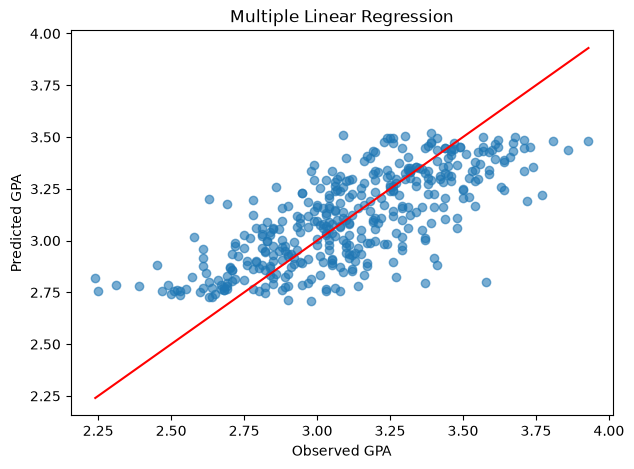

In [21]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    best_pred,
    alpha=0.6
)

lower = min(y_test.min(), best_pred.min())
upper = max(y_test.max(), best_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red"
)

plt.xlabel("Observed GPA")
plt.ylabel("Predicted GPA")
plt.title("Multiple Linear Regression")

plt.show()